# 多少样本能反映变量关系

只用 1° 观测。目录里没有观测 GPP，响应变量仍是 GIMMS LAI，驱动是 `vpd`、`t2m`、`ssrd`、`swvl1`。

模型固定为基准随机森林，解释用 `linear_treeshap`。测试集固定，训练样本量和采样方法改变。

1. 横轴样本量，纵轴测试集 R²，颜色是采样方法。
2. 四个子图是 dependence plot：横轴是变量取值，纵轴是该变量的 SHAP。颜色是样本量。最多样本量的模型当作基准关系，其余样本量到这个基准的距离是同一批点上 SHAP 的均方根误差。这张图用 `random` 采样。

In [1]:
import sys
from pathlib import Path

root = Path.cwd().resolve()
if not (root / "src" / "rf_shap").exists() and (root.parent / "src" / "rf_shap").exists():
    root = root.parent
if str(root / "src") not in sys.path:
    sys.path.insert(0, str(root / "src"))

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from rf_shap.cube.tabular import SampleTable
from rf_shap.explain.shap_explain import compute_shap
from rf_shap.models.registry import build_model
from rf_shap.models.sampling import sample_train
from rf_shap.predict.metrics import regression_metrics

plt.rcParams["font.sans-serif"] = ["PingFang SC", "Arial Unicode MS", "Heiti TC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

OBS = Path("/Users/huangfeini/Documents/esm_case_data/vpd_gpp_1deg/obs")
FILES = {
    "t2m": "era5_monthly_1deg_1980-2014_2m_temperature.nc",
    "vpd": "era5_monthly_1deg_1980-2014_vapour_pressure_deficit.nc",
    "ssrd": "era5_monthly_1deg_1980-2014_surface_solar_radiation_downwards.nc",
    "swvl1": "era5_monthly_1deg_1980-2014_volumetric_soil_water_layer_1.nc",
    "lai": "gimms_lai4g_monthly_1deg_1982-2014.nc",
}
FEATURES = ["vpd", "t2m", "ssrd", "swvl1"]
TARGET = "lai"
SEED = 42
SAMPLE_SIZES = [100, 200, 400, 800, 1600, 3200, 10000]
METHODS = ["random", "stratified", "systematic", "area", "process", "spatial", "fscs", "maximin"]
DEPENDENCE_METHOD = "random"
N_POOL = 12000
N_TEST = 1500
N_EXPLAIN = 200
RF_PARAMS = {"n_estimators": 80, "max_depth": 16, "n_jobs": -1, "min_samples_leaf": 2}

## 1. 读入观测并抽固定的测试集

时间按年月对齐。测试集先抽走，采样只发生在训练池里。

In [2]:
def open_monthly(path):
    dataset = xr.open_dataset(path)
    name = list(dataset.data_vars)[0]
    field = dataset[name].load()
    units = field.attrs.get("units", "")
    dataset.close()
    stamp = pd.to_datetime(field.time.values).to_period("M").to_timestamp()
    field = field.assign_coords(time=stamp.values).groupby("time").mean()
    field.attrs["units"] = units
    field.name = name
    return field

raw = {name: open_monthly(OBS / filename) for name, filename in FILES.items()}
common_time = raw[TARGET].time.values
for field in raw.values():
    common_time = np.intersect1d(common_time, field.time.values)
cubes = {name: field.sel(time=common_time) for name, field in raw.items()}

valid = np.ones(cubes[TARGET].shape, dtype=bool)
for name in FEATURES + [TARGET]:
    valid &= np.isfinite(cubes[name].values)
candidates = np.flatnonzero(valid.reshape(-1))
rng = np.random.default_rng(SEED)
chosen = rng.choice(candidates, size=N_POOL + N_TEST, replace=False)
time_i, lat_i, lon_i = np.unravel_index(chosen, cubes[TARGET].shape)
X = np.column_stack([cubes[name].values[time_i, lat_i, lon_i] for name in FEATURES])
y = cubes[TARGET].values[time_i, lat_i, lon_i]
lat = cubes[TARGET].lat.values[lat_i]
lon = cubes[TARGET].lon.values[lon_i]
when = cubes[TARGET].time.values[time_i]
index = pd.MultiIndex.from_arrays([when, lat, lon], names=["time", "lat", "lon"])
table = SampleTable(X, y, FEATURES, index, y_name=TARGET)

order = rng.permutation(table.n_samples)
test_pos = order[:N_TEST]
pool_pos = order[N_TEST:]
X_pool, y_pool = table.X[pool_pos], table.y[pool_pos]
lat_pool, lon_pool, time_pool = lat[pool_pos], lon[pool_pos], when[pool_pos]
explain_table = table.take(rng.choice(test_pos, size=N_EXPLAIN, replace=False))
print("公共月份", len(common_time), "训练池", len(pool_pos), "测试集", len(test_pos), "解释点", explain_table.n_samples)

公共月份 396 训练池 12000 测试集 1500 解释点 200


## 2. 样本量 × 采样方法

每个组合都在同一测试集上算 R²。`random` 的模型留下来做 dependence plot。

In [3]:
rows = []
random_models = {}
for n_samples in SAMPLE_SIZES:
    for method in METHODS:
        row = {"n_samples": n_samples, "method": method}
        try:
            picked = sample_train(
                X_pool, y_pool, method=method, n_samples=n_samples, seed=SEED,
                lat=lat_pool, lon=lon_pool, time=time_pool,
            )
            train_pos = pool_pos[np.asarray(picked)]
            model = build_model("rf", RF_PARAMS, seed=SEED)
            model.fit(table.X[train_pos], table.y[train_pos])
            metrics = regression_metrics(table.y[test_pos], model.predict(table.X[test_pos]))
            row["r2"] = metrics["r2"]
            row["rmse"] = metrics["rmse"]
            if method == DEPENDENCE_METHOD:
                random_models[n_samples] = model
        except Exception as exc:
            row["error"] = f"{type(exc).__name__}: {exc}"
        rows.append(row)
        print(n_samples, method, {k: row[k] for k in row if k not in {"n_samples", "method"}})

score_table = pd.DataFrame(rows)
score_table

100 random {'r2': 0.6150468767556687, 'rmse': 0.9452559484498482}
100 stratified {'r2': 0.6150629061928812, 'rmse': 0.9452362680294344}
100 systematic {'r2': 0.5776639281434588, 'rmse': 0.9900897931422249}
100 area {'r2': 0.5555613940443472, 'rmse': 1.015667097239079}
100 process {'r2': 0.6150919869667335, 'rmse': 0.9452005625573313}
100 spatial {'r2': 0.624787088517772, 'rmse': 0.9332207410336961}
100 fscs {'r2': 0.6262743068157663, 'rmse': 0.931369417494972}
100 maximin {'r2': 0.54043293948903, 'rmse': 1.032808828851983}
200 random {'r2': 0.6498896013659963, 'rmse': 0.9014631954570687}
200 stratified {'r2': 0.6636865294220875, 'rmse': 0.8835225260400702}
200 systematic {'r2': 0.6676986139877562, 'rmse': 0.8782366798780764}
200 area {'r2': 0.6383930033990397, 'rmse': 0.9161443502589295}
200 process {'r2': 0.6242089806019693, 'rmse': 0.9339393925405739}
200 spatial {'r2': 0.6356870845379938, 'rmse': 0.9195657330521702}
200 fscs {'r2': 0.6014606552981034, 'rmse': 0.9617918584388835}
200

,n_samples,method,r2,rmse
0,100,random,0.615047,0.945256
1,100,stratified,0.615063,0.945236
2,100,systematic,0.577664,0.990090
3,100,area,0.555561,1.015667
4,100,process,0.615092,0.945201
5,100,spatial,0.624787,0.933221
6,100,fscs,0.626274,0.931369
7,100,maximin,0.540433,1.032809
8,200,random,0.649890,0.901463
9,200,stratified,0.663687,0.883523


## 3. R² 随样本量的变化

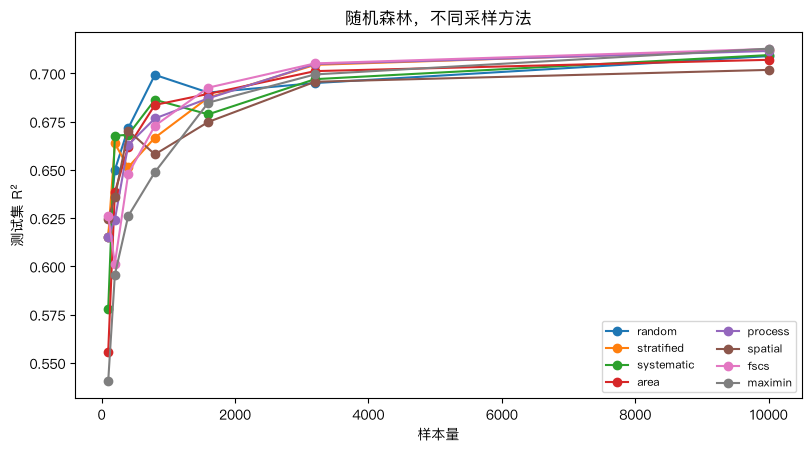

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.4), constrained_layout=True)
colors = dict(zip(METHODS, plt.cm.tab10.colors))
for method in METHODS:
    part = score_table[score_table["method"] == method].sort_values("n_samples")
    ax.plot(part["n_samples"], part["r2"], marker="o", color=colors[method], label=method)
ax.set_xlabel("样本量")
ax.set_ylabel("测试集 R²")
ax.set_title("随机森林，不同采样方法")
ax.legend(ncol=2, fontsize=8)
plt.show()

## 4. Dependence plot 和到最多样本量的距离

同一批解释点上，比较每个样本量模型的 SHAP 和最多样本量模型的 SHAP。距离是逐变量的均方根误差，图例里的 d 是四个变量的平均。

In [5]:
baseline_n = max(random_models)
shap_by_n = {}
for n_samples, model in random_models.items():
    result = compute_shap(
        model, explain_table, method="linear_treeshap", max_samples=None, n_jobs=1, seed=SEED,
    )
    order = np.argsort(result.sample_positions)
    shap_by_n[n_samples] = result.values[order]

baseline = shap_by_n[baseline_n]
distance_rows = []
for n_samples, values in shap_by_n.items():
    per_feature = np.sqrt(np.mean((values - baseline) ** 2, axis=0))
    distance_rows.append({
        "n_samples": n_samples,
        **{feature: float(per_feature[j]) for j, feature in enumerate(FEATURES)},
        "mean_distance": float(per_feature.mean()),
    })
distance_table = pd.DataFrame(distance_rows).sort_values("n_samples")
distance_table

,n_samples,vpd,t2m,ssrd,swvl1,mean_distance
0,100,0.240808,0.346889,0.143109,0.205242,0.234012
1,200,0.181843,0.246634,0.129608,0.157006,0.178773
2,400,0.170253,0.198184,0.117834,0.154372,0.160161
3,800,0.159303,0.170355,0.094538,0.120883,0.136270
4,1600,0.156529,0.148971,0.090377,0.106750,0.125657
5,3200,0.153362,0.135496,0.081469,0.101331,0.117915
6,10000,0.000000,0.000000,0.000000,0.000000,0.000000


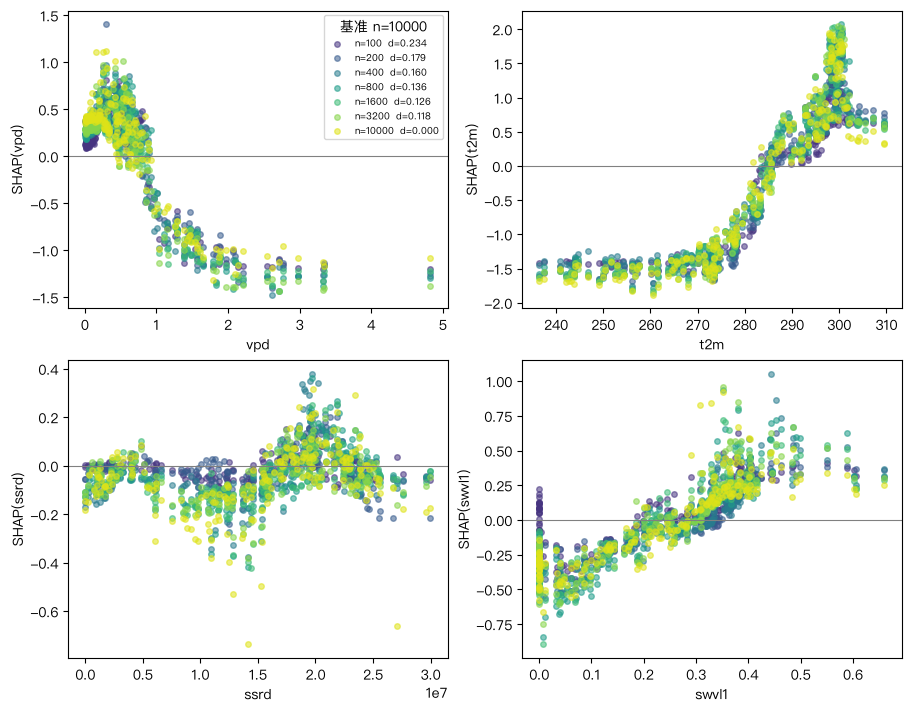

In [6]:
sizes = list(distance_table["n_samples"])
cmap = plt.cm.viridis(np.linspace(0.15, 0.95, len(sizes)))
distance_of = dict(zip(distance_table["n_samples"], distance_table["mean_distance"]))
fig, axes = plt.subplots(2, 2, figsize=(9, 7), constrained_layout=True)
for ax, j in zip(axes.ravel(), range(len(FEATURES))):
    feature = FEATURES[j]
    x = explain_table.X[:, j]
    for color, n_samples in zip(cmap, sizes):
        label = f"n={n_samples}  d={distance_of[n_samples]:.3f}"
        ax.scatter(x, shap_by_n[n_samples][:, j], s=16, alpha=0.55, color=color, label=label)
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_xlabel(feature)
    ax.set_ylabel(f"SHAP({feature})")
axes[0, 0].legend(title=f"基准 n={baseline_n}", fontsize=7)
plt.show()